# Figure S5. The selection of a command as a race among the elements

**What it is.** The time to select an element against its information, the mean time of a command against H, and the wrong selections.

**How it works.** Reads the stored output of the race simulation and fits the lines.

**Files read.** `sim_out/sim_race_results.npz`, `figures/style.py`.

**To run.** Open this notebook from the `notebooks` folder of the repository, or from its root, and run all cells.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
import logging, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
logging.getLogger("matplotlib").setLevel(logging.ERROR)
plt.ioff()
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "figures"), str(ROOT / "code")]

In [2]:
import sys
from pathlib import Path
import numpy as np

from style import Sheet, INK, EDGE, RULE, TONE, share_colour, tb_axes

z = np.load(ROOT / "sim_out" / "sim_race_results.npz")
LN2 = np.log(2.0)
N = 20
BETA = 94.7 / np.log2(N)
UNIT = BETA / LN2
ms = lambda u: u * UNIT

def fit(x, y):
    b, a = np.polyfit(x, y, 1)
    return a, b, float(np.corrcoef(x, y)[0, 1])

S = Sheet(6.5, 2.38)
axA = S.ax(0.42, 0.40, 1.36, 1.72)
axB = S.ax(2.60, 0.40, 1.36, 1.72)
axC = S.ax(4.80, 0.40, 1.36, 1.72)

## A, the time to select an element

In [3]:
ax = axA
I, T = z["I3"], z["TI3"]
x = np.array([0.0, 8.0])
ax.plot(x, 3 + LN2 * x, color=INK, lw=1.2, zorder=2)
ax.scatter(I, T, s=9, c=[share_colour(np.log2(N) - v) for v in I], edgecolors=EDGE, linewidths=0.25, zorder=3)
ax.text(0.3, 5.15, "large share,\nselected early", fontsize=6.2, color=EDGE, ha="left", va="bottom")
ax.text(7.9, 5.85, "small share,\nselected late", fontsize=6.2, color=EDGE, ha="right", va="top")
ax.set_xlabel("information of the element $I_i$, bits", labelpad=1)
ax.set_ylabel(r"selection time, units of $1/v$", labelpad=1.5)
ax.set_xlim(0, 8)
ax.set_ylim(3, 9)
a2 = ax.twinx()
a2.set_ylim(ms(3), ms(9))
a2.set_ylabel("ms", labelpad=2)
tb_axes(ax, xticks=[0, 4, 8], yticks=[3, 6, 9], twin=a2, twin_ticks=[100, 190, 280])
a_, b_, r_ = fit(I, T)
print(f"A: {len(I)} elements, selection time on I_i: intercept {a_:.3f}, slope {b_:.4f} per bit (ln 2 = {LN2:.4f}), r = {r_:.4f}")

A: 106 elements, selection time on I_i: intercept 3.041, slope 0.6983 per bit (ln 2 = 0.6931), r = 0.9838


## B, the mean time of a command

In [4]:
ax = axB
h = np.array([0.8, 5.2])
ax.plot(h, 3 + LN2 * h, color=INK, lw=1.2, zorder=2)
ax.plot(h, 4 + LN2 * h, color=INK, lw=1.0, ls=(0, (3.0, 1.6)), zorder=2)
ax.plot(np.log2(z["Ns"]), z["Tn"], "^", ms=4.2, mfc="white", mec=TONE["scale-free"], mew=0.9, zorder=3, label="even coupling, $N$ = 2 to 32")
ax.plot(z["H3"], z["T3"], "o", ms=3.6, mfc=INK, mec=INK, zorder=4, label=r"practice, $\theta$ = 3")
ax.plot(z["H4"], z["T4"], "s", ms=3.4, mfc="white", mec=INK, mew=0.8, zorder=4, label=r"practice, $\theta$ = 4")
ax.annotate("step 0", xy=(z["H3"][0], z["T3"][0]), xytext=(4.9, 5.1), fontsize=6.0, color=EDGE, ha="right", va="top",
            arrowprops=dict(arrowstyle="-", color=EDGE, lw=0.5))
ax.annotate("step 3,000", xy=(z["H3"][-1], z["T3"][-1]), xytext=(2.5, 3.35), fontsize=6.0, color=EDGE, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=EDGE, lw=0.5))
ax.set_xlabel("averaged information $H$, bits", labelpad=1)
ax.set_ylabel(r"mean time of a command, units of $1/v$", labelpad=1.5)
ax.set_xlim(0.8, 5.2)
ax.set_ylim(3, 8)
ax.legend(fontsize=5.8, loc="upper left", handletextpad=0.2, borderaxespad=0.1, labelspacing=0.2, handlelength=1.0)
b2 = ax.twinx()
b2.set_ylim(ms(3), ms(8))
b2.set_ylabel("ms", labelpad=2)
tb_axes(ax, xticks=[1, 3, 5], yticks=[3, 5.5, 8], twin=b2, twin_ticks=[100, 175, 250])
for th, Hk, Tk in ((3, "H3", "T3"), (4, "H4", "T4")):
    a_, b_, r_ = fit(z[Hk], z[Tk])
    print(f"B: theta = {th}, mean time on H: intercept {a_:.3f}, slope {b_:.4f} per bit, r = {r_:.4f}, "
          f"{b_ * UNIT:.1f} ms per bit (beta = {BETA:.1f}), {ms(z[Tk][0]):.0f} ms at step 0 and {ms(z[Tk][-1]):.0f} ms at step 3,000")
a_, b_, r_ = fit(np.log2(z["Ns"]), z["Tn"])
print(f"B: even coupling, mean time on log2 N: intercept {a_:.3f}, slope {b_:.4f} per bit, r = {r_:.4f}")

B: theta = 3, mean time on H: intercept 3.049, slope 0.6849 per bit, r = 0.9999, 21.7 ms per bit (beta = 21.9), 190 ms at step 0 and 132 ms at step 3,000
B: theta = 4, mean time on H: intercept 4.021, slope 0.7026 per bit, r = 0.9995, 22.2 ms per bit (beta = 21.9), 222 ms at step 0 and 164 ms at step 3,000
B: even coupling, mean time on log2 N: intercept 3.058, slope 0.6861 per bit, r = 0.9997


## C, wrong selections across practice

In [5]:
ax = axC
t = z["steps"]
for th, E, mk, ls, fc in ((3, z["E3"], "o", "-", INK), (4, z["E4"], "s", (0, (3.0, 1.6)), "white")):
    ax.axhline(100 * np.exp(-th), color=RULE, lw=0.8, ls=ls)
    ax.plot(t, 100 * E, marker=mk, ms=3.4, mfc=fc, mec=INK, mew=0.8, color=INK, lw=0.9, ls=ls, zorder=3)
    print(f"C: theta = {th}, wrong selections {100 * E[0]:.1f} percent at step 0 and {100 * E[-1]:.1f} at step 3,000, "
          f"largest {100 * E.max():.1f}, bound {100 * np.exp(-th):.1f}")
ax.text(330, 100 * z["E3"][1] + 0.22, r"$\theta$ = 3", fontsize=6.2, color=INK, ha="left", va="bottom")
ax.text(330, 100 * z["E4"][2] - 0.2, r"$\theta$ = 4", fontsize=6.2, color=INK, ha="left", va="top")
ax.text(2960, 100 * np.exp(-3) + 0.08, r"bound $e^{-\theta}$, $\theta$ = 3", fontsize=6.0, color=EDGE, ha="right", va="bottom")
ax.text(2960, 100 * np.exp(-4) + 0.08, r"bound, $\theta$ = 4", fontsize=6.0, color=EDGE, ha="right", va="bottom")
ax.set_xlabel("practice step $t$", labelpad=1)
ax.set_ylabel("wrong selections, percent", labelpad=1.5)
tb_axes(ax, xticks=[0, 1500, 3000], yticks=[0, 3, 6], xlim=(-60, 3060), ylim=(0, 6))

S.head_over(axA, "A", "Head start of an element")
S.head_over(axB, "B", "One line for novice and expert")
S.head_over(axC, "C", "Reliability held")

C: theta = 3, wrong selections 2.3 percent at step 0 and 1.4 at step 3,000, largest 2.3, bound 5.0
C: theta = 4, wrong selections 0.9 percent at step 0 and 0.6 at step 3,000, largest 0.9, bound 1.8


## The figure

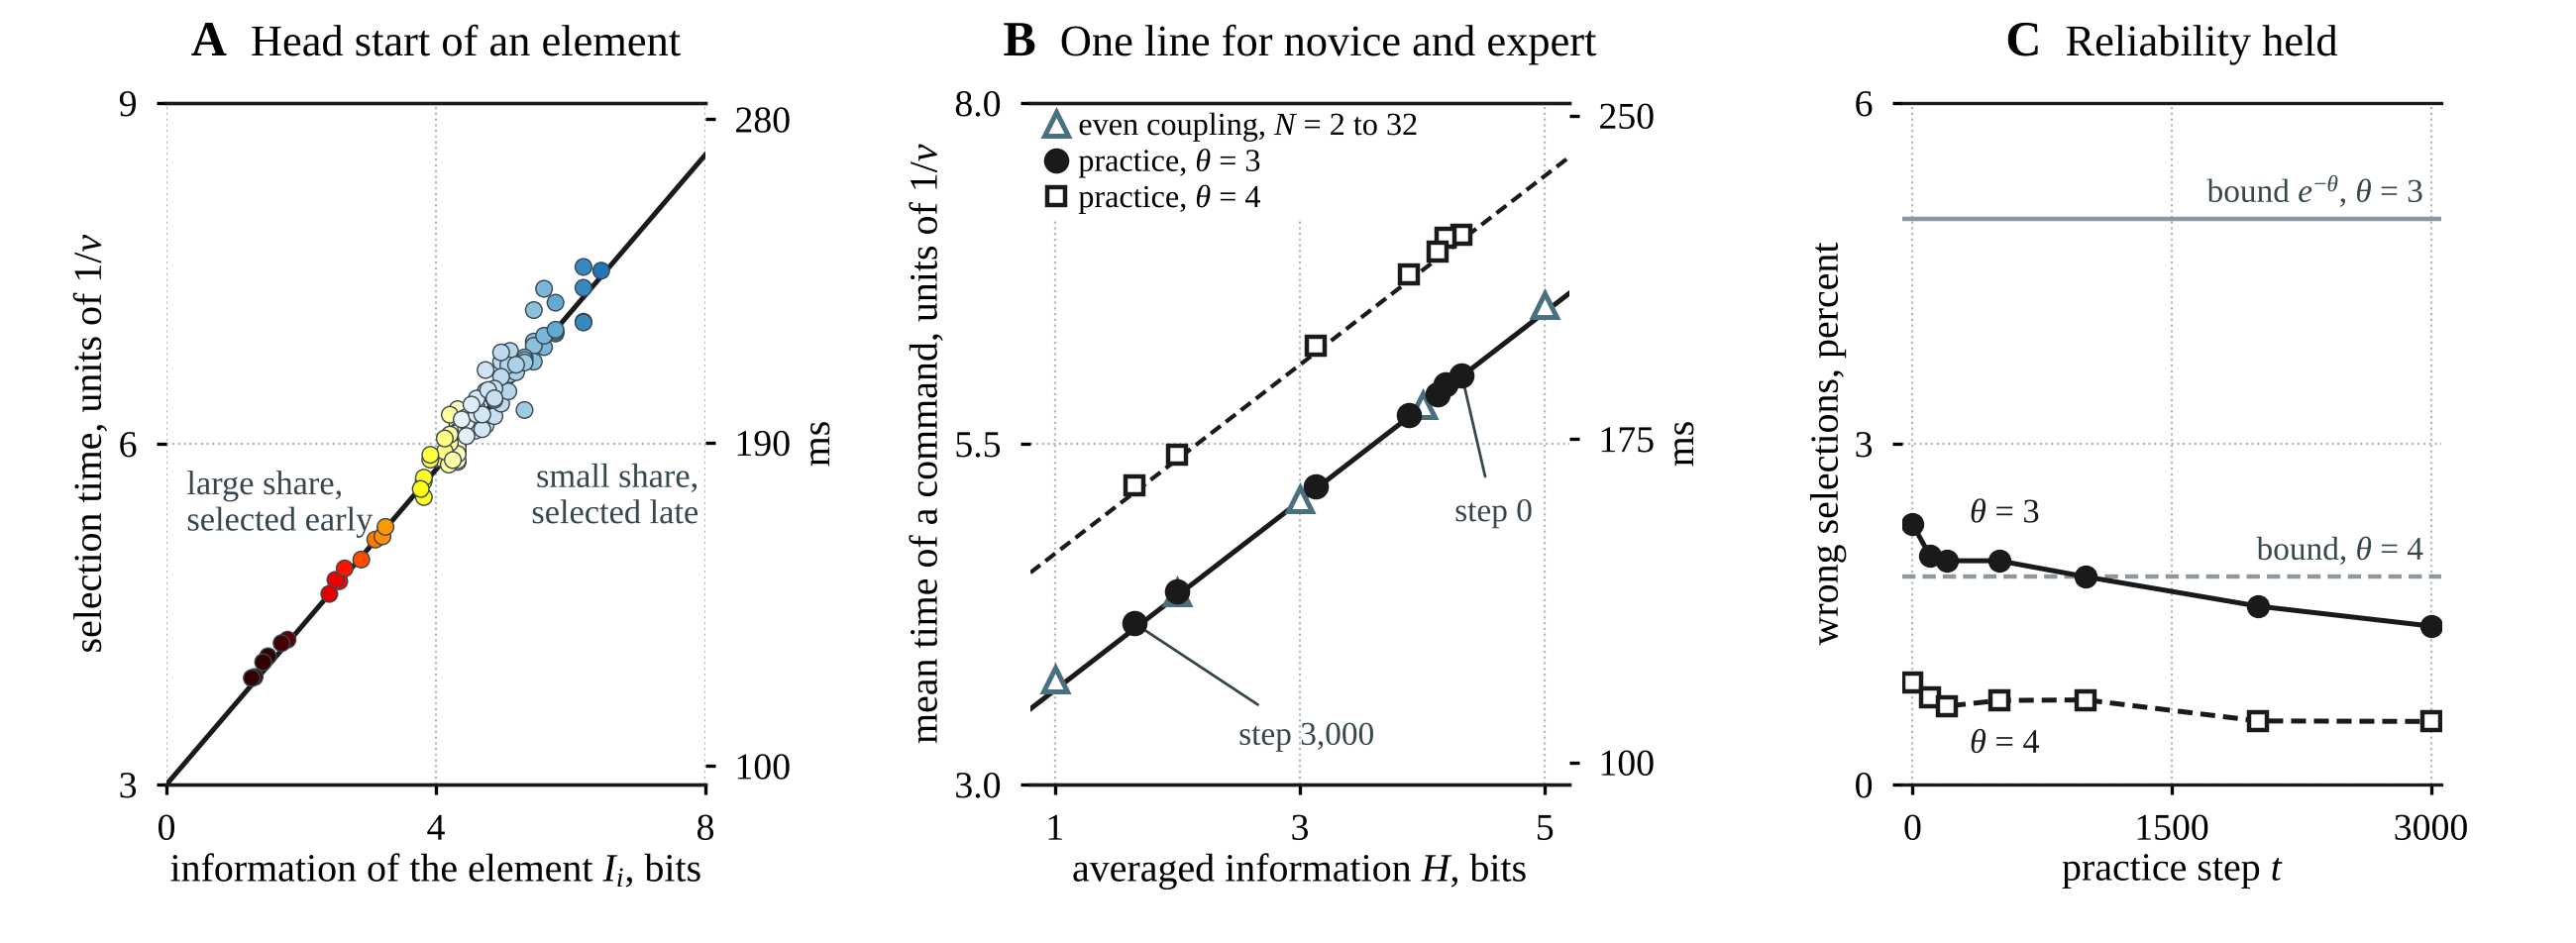

In [6]:
from style import bolden
bolden(S.fig)
display(S.fig)
plt.close("all")

## In the paper

Printed here, then as the manuscript or the Supplemental Material gives it.

- `A`, slope 0.6983, r = 0.9838: 0.698 time units per bit, r = .984 over 106 elements.
- `B: theta = 3`, slope 0.6849, 190 and 132 ms, and `theta = 4`, slope 0.7026: 0.685 and 0.703 against 0.693, r = .9999 and .9995.
- `B: even coupling`, slope 0.6861, r = 0.9997: 0.686 time units per bit.
- `C`: wrong selections between 1.4 and 2.3 percent, and between 0.6 and 0.9 percent.